In [1]:
# 3A. Implement credit card fraud detection for given credit card fraud detection Kaggle
# dataset using Autoencoder and build the model by using the following steps:
# • Dataset: The dataset contains transactions labeled as fraudulent or non-fraudulent, with
# a severe class imbalance.
# • Goal: Identify fraudulent transactions by training an autoencoder only on non-
# fraudulent transactions.
# Steps:
# • Preprocess the data by scaling features (features are already PCA-transformed, so
# they’re anonymized).
# • Train an autoencoder on non-fraudulent transactions to learn typical spending patterns.
# • Calculate reconstruction errors for transactions and set a threshold to detect fraud.
# # • Compile the models with Optimizer, Loss, and Evaluation Metric

In [1]:
import numpy as np 
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report

In [2]:
data = pd.read_csv("/Users/aayushagarwal/Downloads/LP IV Updated Datasets/AutoEncoder/CreditCard/creditcard.csv")
print(data)

            Time         V1         V2        V3        V4        V5  \
0            0.0  -1.359807  -0.072781  2.536347  1.378155 -0.338321   
1            0.0   1.191857   0.266151  0.166480  0.448154  0.060018   
2            1.0  -1.358354  -1.340163  1.773209  0.379780 -0.503198   
3            1.0  -0.966272  -0.185226  1.792993 -0.863291 -0.010309   
4            2.0  -1.158233   0.877737  1.548718  0.403034 -0.407193   
...          ...        ...        ...       ...       ...       ...   
284802  172786.0 -11.881118  10.071785 -9.834783 -2.066656 -5.364473   
284803  172787.0  -0.732789  -0.055080  2.035030 -0.738589  0.868229   
284804  172788.0   1.919565  -0.301254 -3.249640 -0.557828  2.630515   
284805  172788.0  -0.240440   0.530483  0.702510  0.689799 -0.377961   
284806  172792.0  -0.533413  -0.189733  0.703337 -0.506271 -0.012546   

              V6        V7        V8        V9  ...       V21       V22  \
0       0.462388  0.239599  0.098698  0.363787  ... -0.01830

In [3]:
X = data.drop(["Time" , "Class"] , axis=1).values
y = data["Class"].values

In [4]:
x_train , x_test , y_train , y_test = train_test_split(X , y , test_size=0.2 , random_state=42)

In [5]:
x_train = x_train[y_train == 0]
scaler = StandardScaler()
x_train = scaler.fit_transform(x_train)
x_test = scaler.transform(x_test)

In [6]:
class Autoencoder(keras.Model):
    def __init__(self , output_units):
        super().__init__()

        self.encoder = keras.Sequential([
            keras.layers.Dense(64 , activation = "relu"),
            keras.layers.Dropout(0.1),
            keras.layers.Dense(32 , activation = "relu"),
            keras.layers.Dropout(0.1),
            keras.layers.Dense(16 , activation = "relu"),
            keras.layers.Dropout(0.1),
            keras.layers.Dense(8 , activation = "relu"),
        ])

        self.decoder = keras.Sequential([
            keras.layers.Dense(16 , activation = "relu"),
            keras.layers.Dropout(0.1),
            keras.layers.Dense(32 , activation = "relu"),
            keras.layers.Dropout(0.1),
            keras.layers.Dense(64 , activation = "relu"),
            keras.layers.Dropout(0.1),
            keras.layers.Dense(output_units , activation = "softmax"),
        ])

    def call(self , inputs):
        return self.decoder(self.encoder(inputs))

model = Autoencoder(x_train.shape[1])


In [7]:
model.compile(optimizer="adam" , loss="mse")

In [8]:
history = model.fit(x_train , x_train , epochs=10 , batch_size=512 , validation_data=(x_test , x_test))

Epoch 1/10
445/445 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - loss: 0.9494 - val_loss: 0.9564
Epoch 2/10
445/445 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - loss: 0.9242 - val_loss: 0.9526
Epoch 3/10
445/445 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.9220 - val_loss: 0.9509
Epoch 4/10
445/445 ━━━━━━━━━━━━━━━━━━━━ 0s 999us/step - loss: 0.9199 - val_loss: 0.9488
Epoch 5/10
445/445 ━━━━━━━━━━━━━━━━━━━━ 0s 988us/step - loss: 0.9185 - val_loss: 0.9477
Epoch 6/10
445/445 ━━━━━━━━━━━━━━━━━━━━ 0s 985us/step - loss: 0.9176 - val_loss: 0.9468
Epoch 7/10
445/445 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.9168 - val_loss: 0.9463
Epoch 8/10
445/445 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.9163 - val_loss: 0.9456
Epoch 9/10
445/445 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.9158 - val_loss: 0.9453
Epoch 10/10
445/445 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.9155 - val_loss: 0.9449


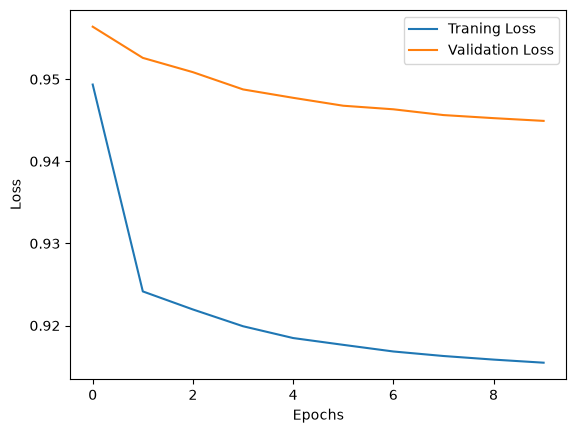

In [9]:
plt.plot(history.history["loss"] , label = "Traning Loss")
plt.plot(history.history["val_loss"] , label = "Validation Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()

In [10]:
def get_errors(original , reconstructed):
    return np.mean(
        (original - reconstructed) ** 2 , axis = 1
    )

In [11]:
train_errors = get_errors(x_train , model.predict(x_train , verbose=0))

In [12]:
threshold = np.percentile(train_errors , 95)
print(threshold)

1.8674392713986436


In [13]:
test_errors = get_errors(x_test , model.predict(x_test , verbose = 0))
predictions = np.where(test_errors > threshold , 1 ,0)


In [14]:
print(classification_report(y_test , predictions , target_names=["Normal" , "fraud"]))

              precision    recall  f1-score   support

      Normal       1.00      0.95      0.97     56864
       fraud       0.03      0.91      0.06        98

    accuracy                           0.95     56962
   macro avg       0.51      0.93      0.52     56962
weighted avg       1.00      0.95      0.97     56962

